In [1]:
import importlib
import sys
from pathlib import Path

import pandas as pd
from IPython.display import display

sys.path.insert(0, "kev")

import data.persona as _persona_mod
import data.base as _base_mod
import data.issp as _issp_mod
import data.twin2k as _twin2k_mod
import data.grummon as _grummon_mod
import models.kev_pointer as _kev_pointer_mod
import training.plotter as _plotter_mod
import training.trainer as _trainer_mod
import training as _training_pkg

for _mod in (
    _persona_mod,
    _base_mod,
    _issp_mod,
    _twin2k_mod,
    _grummon_mod,
    _kev_pointer_mod,
    _plotter_mod,
    _trainer_mod,
    _training_pkg,
):
    importlib.reload(_mod)

from data.base import build_eval_set, build_persona_dataset
from data.grummon import load_grummon
from data.issp import load_issp_df
from data.twin2k import load_twin2k_df
from training import GroupedTrainer, free_gpu

## 1. Load & Build Persona Datasets

In [2]:
INCLUDE_COUNTRY = False

VALID_ISSP_QIDS = ["2020:v12", "2020:v6", "2020:v28", "2020:v42"]
VALID_TWIN_QIDS = [f"twin2k:QID9_{i:03d}" for i in range(89, 100)] + ["twin2k:QID41", "twin2k:QID163", "twin2k:QID165"]
VALID_QIDS = VALID_ISSP_QIDS + VALID_TWIN_QIDS

all_df = pd.concat([load_issp_df(), load_twin2k_df()], ignore_index=True)
if not set(VALID_QIDS) <= set(all_df["qid"]):
    raise KeyError(f"Valid qids not found: {sorted(set(VALID_QIDS) - set(all_df['qid']))}")

train_records = build_persona_dataset(
    all_df[~all_df["qid"].isin(VALID_QIDS)], attr_sets=None, include_country=INCLUDE_COUNTRY, desc="train_records_resp"
)
valid_grouped = build_eval_set(
    all_df[all_df["qid"].isin(VALID_QIDS)],
    attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, name="valid", valid=True,
)
grummon_grouped = load_grummon(attr_sets=None, include_country=INCLUDE_COUNTRY, grouped=True, valid=False)

eval_records = [valid_grouped, grummon_grouped]

print(
    f"Train records : {len(train_records):,}\n"
    f"Eval sets     : valid={len(valid_grouped['records']):,} ({len(valid_grouped['packed_views']):,} states), "
    f"grummon={len(grummon_grouped['records']):,} ({len(grummon_grouped['packed_views']):,} states)"
)

Loaded 1,881,950 records from train_records_resp_minNone_5099daf2.pkl
Loaded 13,183 records from valid_records_minNone_dc60d6c3.pkl
Train records : 1,881,950
Eval sets     : valid=13,183 (3,879 states), grummon=33,798 (3,652 states)


## 2. Configure & Instantiate `GroupedTrainer`


In [3]:
resume = False
val_every = 50
epochs = 1
lr = 5e-5
# Choose model preset ("9b" or "0.8b"):
PRESET = "0.8b"

if PRESET == "9b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-9b",
        save_dir="runs/kev-9b-resp-issp+twin2k-grouped-newvalid",
        weights_dtype="bf16",
        use_bf16=True,
        gradient_checkpointing=True,
        max_questions_per_group=96,
        max_chars_per_group=36_000,
        eval_batch_size=64,
    )
elif PRESET == "0.8b":
    trainer_cfg = dict(
        base_model="jaredpalmer/kev-0.8b",
        save_dir="runs/kev-0.8b-resp-issp+twin2k-grouped-newvalid",
        weights_dtype="fp32",
        use_bf16=False,
        gradient_checkpointing=False,
        max_questions_per_group=32,
        max_chars_per_group=20_000,
        eval_bf16=True,  # bf16 autocast for eval only; training stays fp32
        eval_batch_size=128,
    )
else:
    raise ValueError(f"Unknown PRESET: {PRESET!r}")

trainer = None
free_gpu()

trainer = GroupedTrainer(
    train_records=train_records,
    eval_records=eval_records,
    lora_rank=64,
    epochs=epochs,
    lr=lr,
    batch_size=1,
    grad_accum_steps=12,
    warmup_steps=2000,
    val_every=val_every,
    samples_per_epoch=None,
    resume=resume,
    **trainer_cfg,
)

display(pd.Series(trainer.describe(), name="trainer_config").to_frame())

Reconstructing (incomplete total...): |          |  0.00B /  0.00B            

Fetching 9 files:   0%|          | 0/9 [00:00<?, ?it/s]

Loading weights:   0%|          | 0/320 [00:00<?, ?it/s]

,trainer_config
run_name,kev-0.8b-resp-issp+twin2k-grouped-newvalid
base,Qwen/Qwen3.5-0.8B-Base
lora_rank,64
mode,lora_rank 64
weights_dtype,fp32
use_bf16,False
eval_bf16,True
gradient_checkpointing,False
max_questions_per_group,32
max_chars_per_group,20000


## 3. Train

`trainer.train()` initializes the composed `TrainingPlotter` display, runs the grouped shared-prefix training loop, saves `best`/`last` checkpoints and lightweight `trainer_state.pt`, and automatically frees optimizer/scheduler/gradient buffers in `finally:`.

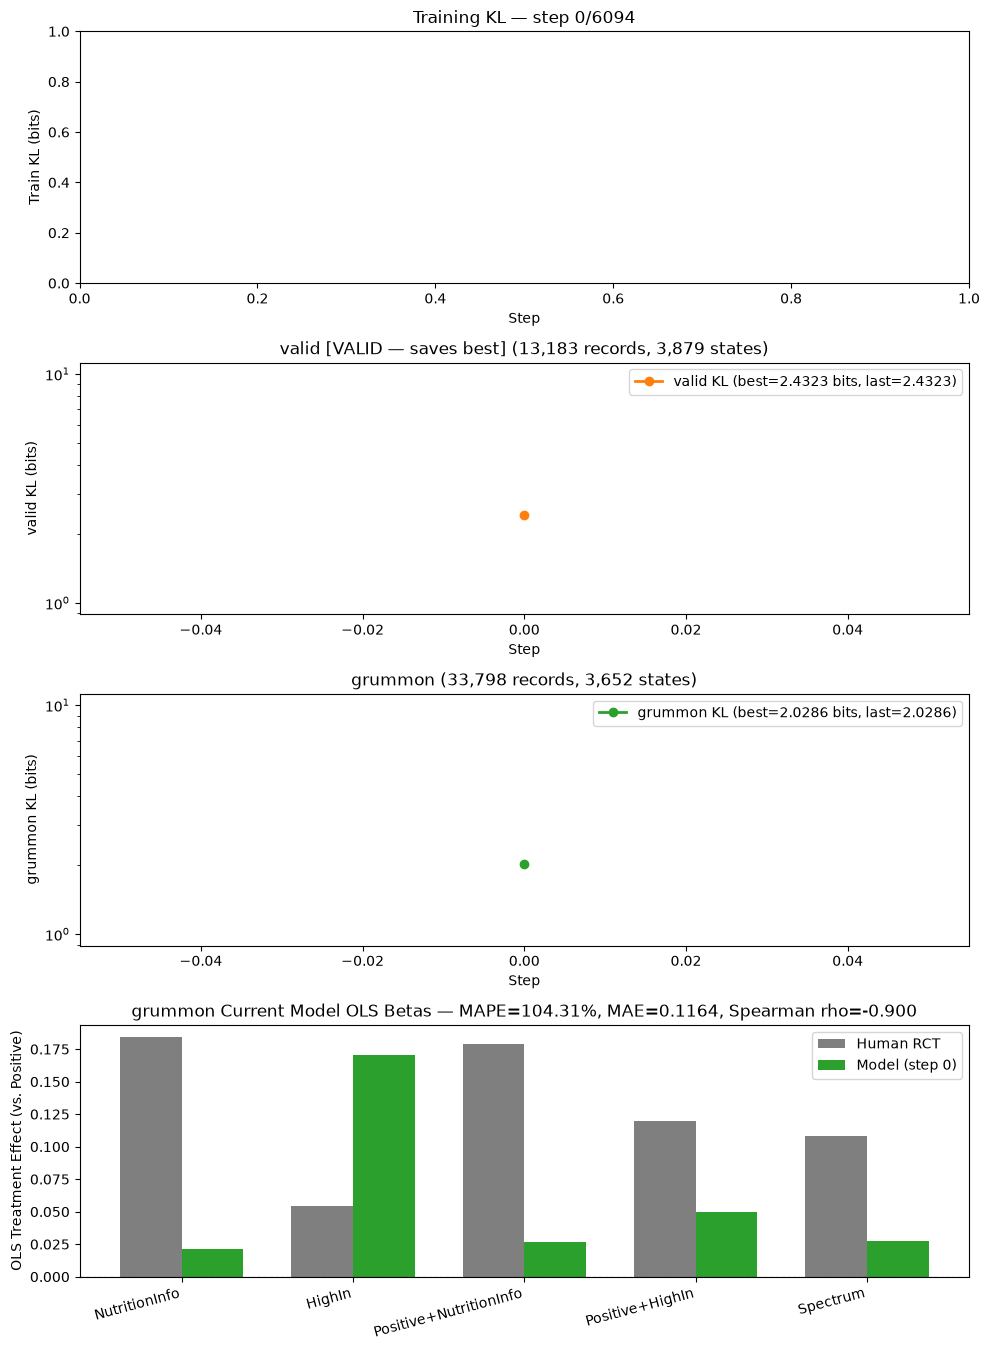

,epoch,step,train_kl,valid_kl,grummon_kl,grummon_OLS MAPE (%),grummon_OLS MAE,grummon_OLS MSE,grummon_Spearman rho
0,0,0,—,2.4323,2.0286,104.31,0.1164,0.0149,-0.9000


,human,model,abs_diff
NutritionInfo,0.1844,0.0216,0.1629
HighIn,0.0541,0.1704,0.1163
Positive+NutritionInfo,0.1788,0.0268,0.1521
Positive+HighIn,0.1194,0.0494,0.0700
Spectrum,0.1083,0.0276,0.0807


KeyboardInterrupt: 

In [4]:
plotter = trainer.train()

## Optional: Probe VRAM directly on `trainer`

`trainer.probe_vram(grid)` reuses `trainer.train_one_step` with a zero-LR AdamW optimizer (and 2 micro-batches when `grad_accum_steps > 1`) inside `torch.random.fork_rng` so it measures exact steady-state peak VRAM without mutating model weights, RNG state, or creating empty plots.

In [8]:
df_probe = trainer.probe_vram([
    (32, 16_000),
    (32, 20_000),
    (32, 24_000),
    (64, 24_000),
    (96, 36_000),
    (128, 48_000),
    (160, 60_000),
])
display(df_probe)

# You can also update grouping on the fly and recompute the schedule:
# trainer.set_grouping(max_questions_per_group=160, max_chars_per_group=60_000)

GPU: NVIDIA GeForce RTX 5090 (31.4 GiB total)
mq= 32, mc= 16000 -> OK  | peak_alloc=20.92 GiB (reserved=21.64 GiB) | worst=(26, 110, 131) (3,516 toks) | 1ep_steps=6,693
mq= 32, mc= 20000 -> OK  | peak_alloc=25.52 GiB (reserved=25.94 GiB) | worst=(20, 105, 221) (4,525 toks) | 1ep_steps=6,094
mq= 32, mc= 24000 -> OOM | peak_alloc=27.97 GiB (reserved=28.04 GiB) | worst=(32, 102, 158) (5,158 toks) | 1ep_steps=5,771


,max_questions,max_chars,groups_per_epoch,mean_q_per_group,steps_per_epoch,total_steps_1ep,"worst_(Q, Ls, Lb)",worst_padded_toks,peak_alloc_GiB,peak_reserved_GiB,status
0,32,16000,80307,23.43,6693,6693,"(26, 110, 131)",3516,20.92,21.64,OK
1,32,20000,73125,25.74,6094,6094,"(20, 105, 221)",4525,25.52,25.94,OK
2,32,24000,69249,27.18,5771,5771,"(32, 102, 158)",5158,27.97,28.04,OOM


## Show train records for epoch 1 based on seed 

In [ ]:
import random
from data.base import group_train_records


def epoch1_question_order(seed):
    epoch_rng = random.Random(f"{seed}:epoch:0")
    sampled = (
        epoch_rng.sample(train_records, trainer.n_per_epoch)
        if trainer.samples_per_epoch is not None
        else train_records
    )
    groups = group_train_records(
        sampled,
        max_questions=trainer_cfg["max_questions_per_group"],
        max_chars=trainer_cfg["max_chars_per_group"],
        rng=epoch_rng,
    )
    bs = trainer.effective_groups_bs
    return pd.DataFrame(
        [
            {
                "step": (group_idx // bs) + 1,
                "group_idx": group_idx,
                "n_questions": len(g),
                "persona": g[0]["persona"],
                "qids": [r["qid"] for r in g],
            }
            for group_idx, g in enumerate(groups)
        ]
    )


In [ ]:
SEED_TO_CHECK = 0
df_order = epoch1_question_order(SEED_TO_CHECK)
print(
    f"seed={SEED_TO_CHECK} | groups={len(df_order):,} | "
    f"steps={df_order['step'].max():,} | questions={df_order['n_questions'].sum():,}"
)
display(df_order)

seed=0 | groups=42,219 | steps=3,519 | questions=1,881,950


,step,group_idx,n_questions,persona,qids
0,1,0,62,"Sex=Male, Age=50-64, Education=College graduat...","[2018:v24, 2018:v23, 2018:v63, 2018:v22, 2018:..."
1,1,1,47,"Sex=Female, Age=30-49, Education=High school o...","[2024:v23, 2024:v24, 2024:v30, 2024:v26, 2024:..."
2,1,2,1,"Sex=Female, Age=65+, Education=College graduat...",[twin2k:QID57]
3,1,3,35,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID278_5, twin2k:QID277_12, twin2k:QID..."
4,1,4,96,"Sex=Female, Age=18-29, Education=High school o...","[twin2k:QID148, twin2k:QID169, twin2k:QID275, ..."
...,...,...,...,...,...
42214,3518,42214,73,"Sex=Female, Age=50-64, Education=College gradu...","[twin2k:QID233_5, twin2k:QID26_8, twin2k:QID9_..."
42215,3518,42215,75,"Sex=Male, Age=18-29, Education=High school or ...","[twin2k:QID171, twin2k:QID233_3, twin2k:QID9_0..."
42216,3519,42216,54,"Sex=Female, Age=50-64, Education=High school o...","[2017:v54, 2017:v55, 2017:v42, 2017:v60, 2017:..."
42217,3519,42217,54,"Sex=Male, Age=50-64, Education=College graduat...","[2017:v54, 2017:v55, 2017:v42, 2017:v60, 2017:..."


In [ ]:
SEED_TO_CHECK = 1
df_order = epoch1_question_order(SEED_TO_CHECK)
print(
    f"seed={SEED_TO_CHECK} | groups={len(df_order):,} | "
    f"steps={df_order['step'].max():,} | questions={df_order['n_questions'].sum():,}"
)
display(df_order)

seed=1 | groups=42,219 | steps=3,519 | questions=1,881,950


,step,group_idx,n_questions,persona,qids
0,1,0,96,"Sex=Female, Age=30-49, Education=College gradu...","[twin2k:QID148, twin2k:QID167, twin2k:QID275, ..."
1,1,1,62,"Sex=Male, Age=65+, Education=College graduate/...","[twin2k:QID245_5, twin2k:QID245_4, twin2k:QID2..."
2,1,2,55,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID150, twin2k:QID236_5, twin2k:QID236..."
3,1,3,62,"Sex=Female, Age=30-49, Education=College gradu...","[2018:v24, 2018:v23, 2018:v63, 2018:v22, 2018:..."
4,1,4,21,"Sex=Male, Age=50-64, Education=Associate's deg...","[twin2k:QID29_22, twin2k:QID29_17, twin2k:QID2..."
...,...,...,...,...,...
42214,3518,42214,6,"Sex=Male, Age=30-49, Education=College graduat...","[2017:v22, 2017:v48, 2017:v52, 2017:v50, 2017:..."
42215,3518,42215,56,"Sex=Male, Age=65+, Education=College graduate/...","[2021:v52, 2021:v40, 2021:v42, 2021:v51, 2021:..."
42216,3519,42216,73,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID9_276, twin2k:QID31, twin2k:QID25_4..."
42217,3519,42217,96,"Sex=Male, Age=30-49, Education=College graduat...","[twin2k:QID148, twin2k:QID167, twin2k:QID275, ..."
